# Stage 3: malignant cells near and far from TILs

For each of the three 480-gene samples (MH065_480, MH106_480, MH107_480), malignant cells are taken from two fixed regions: one next to a TIL-rich area (`wTIL`) and one away from it (`noTIL`). They're compared by Wilcoxon DE and pathway scores, and the scores are compared across the three samples with paired t-tests.

The analysis follows the original notebooks for the three samples and the original TIL plotting notebook, starting from the final Stage 1 objects. PCA, UMAP and Leiden clustering are left out: no output depends on them.

## Parameters

In [1]:
import os

STAGE1_DIR = "/path/to/stage1_output"  # one subfolder per sample, with <sample>.h5ad
OUTPUT_DIR = "/path/to/stage3_output/malignant_TIL"
FIGURE_DIR = os.path.join(OUTPUT_DIR, "figures")
# The original subset objects, used only for the check at the end; set to None to skip it
ARCHIVED_DIR = "/path/to/original_subsets"
archived_files = {
    "MH065_480": "MH065_malignant_SUBSET_wTILs_DE_Jan26.h5ad",
    "MH106_480": "MH106_malignant_SUBSET_wTILs_DE_Jan26.h5ad",
    "MH107_480": "MH107_malignant_SUBSET_wTILs_DE_Jan26.h5ad",
}

# Regions as (x_min, x_max, y_min, y_max) in µm, from the original notebooks
regions = {
    "MH065_480": {"noTIL": (6400, 7400, 2200, 3000), "wTIL": (8800, 10000, 1200, 3200)},
    "MH106_480": {"noTIL": (2200, 3400, 3000, 3900), "wTIL": (5500, 5950, 1800, 3000)},
    "MH107_480": {"noTIL": (6400, 7000, 1600, 2800), "wTIL": (8600, 9400, 800, 2900)},
}
PAIRED_SAMPLES = ["MH065_480", "MH106_480", "MH107_480"]

In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import scanpy as sc
import squidpy as sq
import anndata as ad
from scipy.stats import ttest_rel

os.makedirs(FIGURE_DIR, exist_ok=True)
sc.settings.figdir = FIGURE_DIR

~/miniconda3/envs/xenium.squidpy/lib/python3.9/site-packages/pandas/core/arrays/masked.py:61: UserWarning: Pandas requires version '1.3.6' or newer of 'bottleneck' (version '1.3.5' currently installed).
  from pandas.core import (
~/miniconda3/envs/xenium.squidpy/lib/python3.9/site-packages/dask/dataframe/_pyarrow_compat.py:15: FutureWarning: Minimal version of pyarrow will soon be increased to 14.0.1. You are using 13.0.0. Please consider upgrading.
  warnings.warn(
~/miniconda3/envs/xenium.squidpy/lib/python3.9/site-packages/numba/core/decorators.py:246: RuntimeWarning: nopython is set for njit and is ignored
  warnings.warn('nopython is set for njit and is ignored', RuntimeWarning)


## Pathway gene sets

In [3]:
pathway_gene_sets = {
    "NOTCH": ['JAG1','NF2','BCORL1'], #from: https://www.nature.com/articles/s41575-019-0109-y
    "TGFB" : ['SMAD3','SMAD4','TGFBR1','TGFBR2','AVCR1B','ACVR2A'],#from: https://www.nature.com/articles/s41575-019-0109-y
    "IL6":["IL6","IL6R","IL6ST","STAT3","TNFRSF1A","TNFRSF21","JUN","SOCS3"], #checked
    "SQUAMOUS" : ['HK2',"KRT5","GATA6","TP63","TRIM29"], # Bailey et al., 2016
    "INFLAMMATORY": ['CCL2','IL1B','NLRP3'],
    "OXPHOS" : ["NDUFS1","ATP5F1A","ATP1B1","COX5A","UQCRC2","UQCRC1","POR","NDUFV1"],
    "IFNG" : ["CMPK2","DDX60","GBP4","IDO1","IFIT1","IFIT2","IFIT3","ISG15","OASL","RSAD2","ZBP1"],
    "HYPOXIA":["VEGFA","LDHA","SLC2A1","ARNT","ERO1A","HIF1A","CA9"],
    "TREATMENT" :['IL1A','NRG1','ERBB2','TRAF2'], #Hwang et al., 
    "TNF": ["ABCB1","TRAF1","PIK3CD","TRAF3","CHUK","RIPK1","CASP8","CREB1","TRAF5","TRADD","TNF","TNFRSF1B","MLKL","TNFRSF10B","BIRC2","BIRC3"],
    "TNF_NFKB" : ["CXCL2","CXCL3","IRF1","LAMB3","NFKB1","NFKB2","NFKBIA","SOD2","PLAU","PLAUR","TNFAIP2","TNFAIP3","TNIP1","TRAF1","BTG2","IFIH1"],
    "WNT": ["WNT6","PTCH1","TCF7","LEF1","AXIN2"],
    "TIGIT":['PVR','NECTIN2','NECTIN3','NECTIN4'],
    "PD1" : ['CD274','PDCD1LG2'],
    "STIM" : ['TNFSF9','TNFRSF14']
}

## 1. Malignant cells in each region

A cell is included if both `cell_class_threshold` and `anno` are "Malignant cells", as in the original 480-gene notebooks. The counts are re-normalised within the two regions, then compared with a Wilcoxon test.

In [4]:
def region_cells(adata, box):
    x_min, x_max, y_min, y_max = box
    return (
        (adata.obs['x_centroid'] >= x_min) & (adata.obs['x_centroid'] <= x_max) &
        (adata.obs['y_centroid'] >= y_min) & (adata.obs['y_centroid'] <= y_max)
    )


def malignant_regions(sample):
    adata = sc.read_h5ad(os.path.join(STAGE1_DIR, sample, f"{sample}.h5ad"))
    malignant = (adata.obs['cell_class_threshold'] == "Malignant cells") & (adata.obs['anno'] == "Malignant cells")
    parts = []
    for region, box in regions[sample].items():
        part = adata[region_cells(adata, box) & malignant]
        # Raw counts, re-normalised below
        sub = ad.AnnData(
            X=part.layers["counts"].copy(),
            obs=part.obs[["x_centroid", "y_centroid", "cell_class_threshold", "anno"]].copy(),
            var=pd.DataFrame(index=part.var_names),
        )
        sub.obsm["spatial"] = np.asarray(part.obsm["spatial"]).copy()
        sub.obs["Region"] = region
        parts.append(sub)
    merged = ad.concat(parts, merge="same")
    merged.obs["Region"] = merged.obs["Region"].astype("category")
    print(sample, merged.obs["Region"].value_counts().to_dict())
    return merged


def analyse(merged):
    merged.layers["counts"] = merged.X.copy()
    sc.pp.normalize_total(merged, inplace=True)
    sc.pp.log1p(merged)
    merged.layers['scaled'] = sc.pp.scale(merged, copy=True).X
    sc.tl.rank_genes_groups(merged, 'Region', method='wilcoxon')
    for pathway, genes in pathway_gene_sets.items():
        if not set(genes) & set(merged.var_names):
            print(f"  {pathway}: no genes in this panel, not scored")
            continue
        sc.tl.score_genes(merged, gene_list=genes, ctrl_size=20, random_state=22, score_name=f"{pathway}_pathway_score")
    return merged


def de_table(merged):
    result = merged.uns['rank_genes_groups']
    return pd.DataFrame({
        f"{group}_{key}": result[key][group]
        for group in result['names'].dtype.names
        for key in ['names', 'scores', 'pvals', 'pvals_adj', 'logfoldchanges']
    })


subsets = {}
for sample in regions:
    subsets[sample] = analyse(malignant_regions(sample))
    de_table(subsets[sample]).to_csv(os.path.join(OUTPUT_DIR, f"{sample}_malignant_wTIL_vs_noTIL_DE.csv"), index=False)
    subsets[sample].write_h5ad(os.path.join(OUTPUT_DIR, f"{sample}_malignant_TIL_regions.h5ad"))

MH065_480 {'wTIL': 1664, 'noTIL': 1462}


~/miniconda3/envs/xenium.squidpy/lib/python3.9/site-packages/numpy/core/fromnumeric.py:84: FutureWarning: The behavior of DataFrame.sum with axis=None is deprecated, in a future version this will reduce over both axes and return a scalar. To retain the old behavior, pass axis=0 (or do not pass axis)
  return reduction(axis=axis, out=out, **passkwargs)


MH106_480 {'noTIL': 1727, 'wTIL': 544}


~/miniconda3/envs/xenium.squidpy/lib/python3.9/site-packages/numpy/core/fromnumeric.py:84: FutureWarning: The behavior of DataFrame.sum with axis=None is deprecated, in a future version this will reduce over both axes and return a scalar. To retain the old behavior, pass axis=0 (or do not pass axis)
  return reduction(axis=axis, out=out, **passkwargs)


MH107_480 {'noTIL': 1179, 'wTIL': 541}


~/miniconda3/envs/xenium.squidpy/lib/python3.9/site-packages/numpy/core/fromnumeric.py:84: FutureWarning: The behavior of DataFrame.sum with axis=None is deprecated, in a future version this will reduce over both axes and return a scalar. To retain the old behavior, pass axis=0 (or do not pass axis)
  return reduction(axis=axis, out=out, **passkwargs)


MH106_314 {'noTIL': 5178, 'wTIL': 771}


~/miniconda3/envs/xenium.squidpy/lib/python3.9/site-packages/numpy/core/fromnumeric.py:84: FutureWarning: The behavior of DataFrame.sum with axis=None is deprecated, in a future version this will reduce over both axes and return a scalar. To retain the old behavior, pass axis=0 (or do not pass axis)
  return reduction(axis=axis, out=out, **passkwargs)


## 2. DE heatmaps

~/miniconda3/envs/xenium.squidpy/lib/python3.9/site-packages/numpy/core/fromnumeric.py:84: FutureWarning: The behavior of DataFrame.sum with axis=None is deprecated, in a future version this will reduce over both axes and return a scalar. To retain the old behavior, pass axis=0 (or do not pass axis)
  return reduction(axis=axis, out=out, **passkwargs)


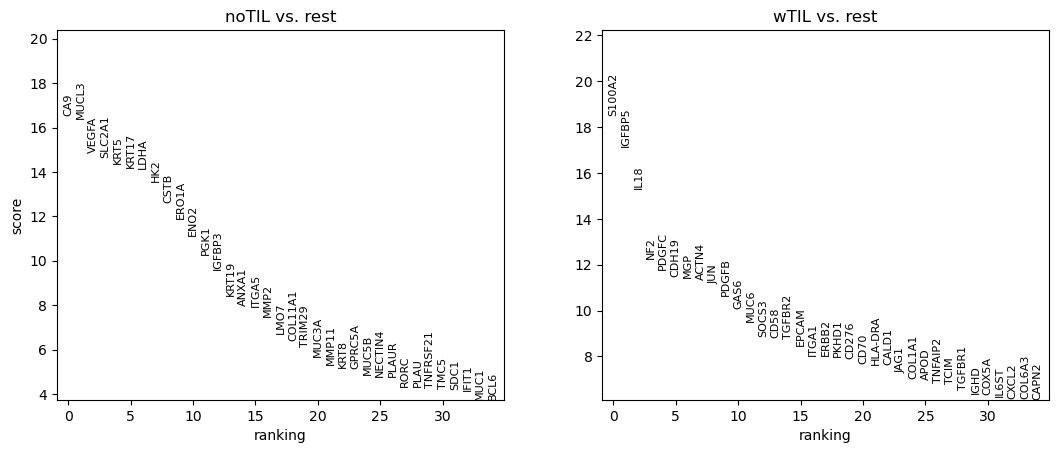

In [6]:
# Find Marker genes
sc.tl.rank_genes_groups(subsets["MH107_480"], 'Region', method='wilcoxon')
sc.pl.rank_genes_groups(subsets["MH107_480"], n_genes=35, sharey=False)

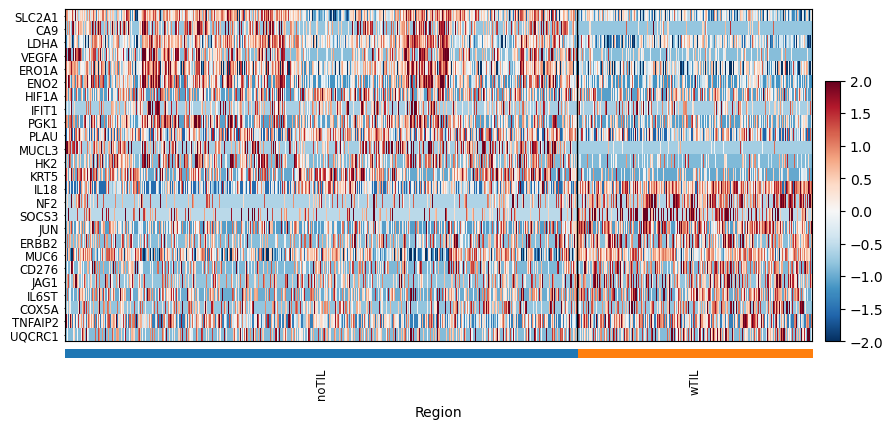

In [5]:
features = ['SLC2A1', 'CA9', 'LDHA', 'VEGFA', 'ERO1A', 'ENO2', 'HIF1A', 'IFIT1', 'PGK1', 'PLAU', 'MUCL3', 'HK2', 'KRT5', 'IL18', 'NF2', 'SOCS3', 'JUN', 'ERBB2', 'MUC6', 'CD276', 'JAG1', 'IL6ST', 'COX5A', 'TNFAIP2', 'UQCRC1']
sc.pl.heatmap(
    subsets["MH107_480"],
    var_names=features,
    groupby='Region',
    layer='scaled',
    swap_axes=True,
    cmap='RdBu_r',
    vmax = 2,
    vmin = -2,
    save = '_Fig5_MH107_TIL_topDE.pdf'
)

~/miniconda3/envs/xenium.squidpy/lib/python3.9/site-packages/numpy/core/fromnumeric.py:84: FutureWarning: The behavior of DataFrame.sum with axis=None is deprecated, in a future version this will reduce over both axes and return a scalar. To retain the old behavior, pass axis=0 (or do not pass axis)
  return reduction(axis=axis, out=out, **passkwargs)


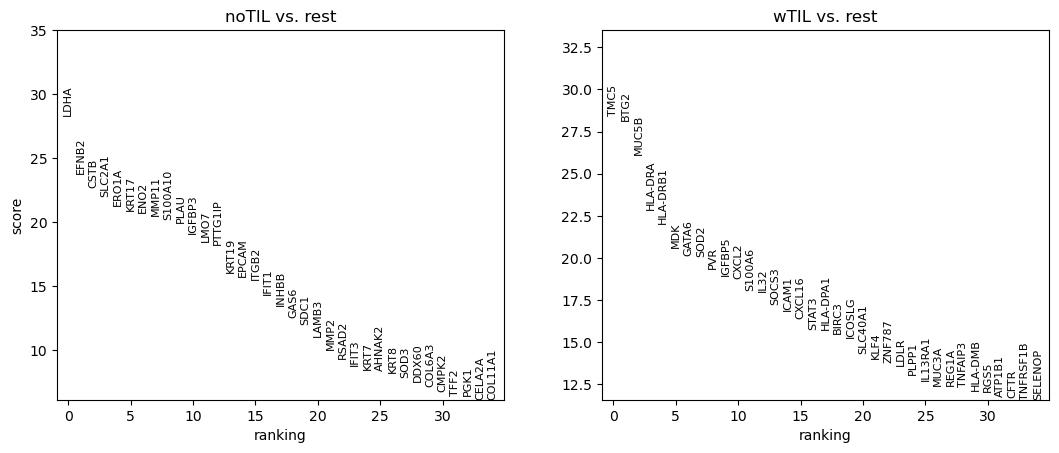

In [8]:
# Find Marker genes
sc.tl.rank_genes_groups(subsets["MH065_480"], 'Region', method='wilcoxon')
sc.pl.rank_genes_groups(subsets["MH065_480"], n_genes=35, sharey=False)

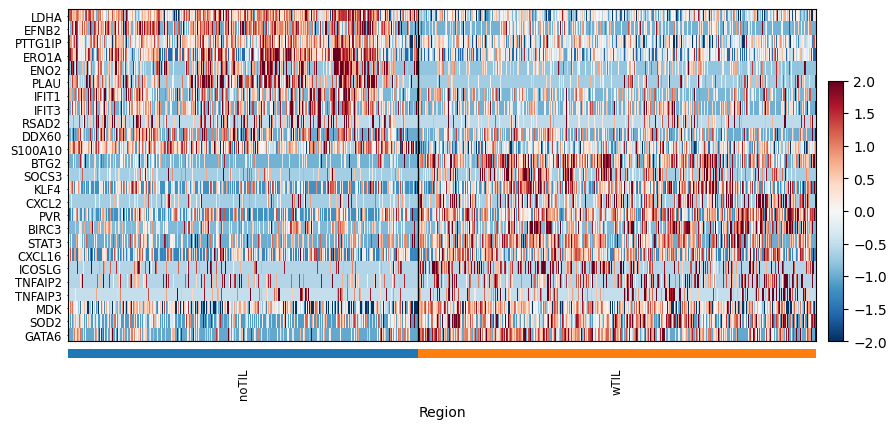

In [7]:
features = ['LDHA', 'EFNB2', 'PTTG1IP', 'ERO1A', 'ENO2', 'PLAU', 'IFIT1', 'IFIT3', 'RSAD2', 'DDX60', 'S100A10', 'BTG2', 'SOCS3', 'KLF4', 'CXCL2', 'PVR', 'BIRC3', 'STAT3', 'CXCL16', 'ICOSLG', 'TNFAIP2', 'TNFAIP3', 'MDK', 'SOD2', 'GATA6']
sc.pl.heatmap(
    subsets["MH065_480"],
    var_names=features,
    groupby='Region',
    layer='scaled',
    swap_axes=True,
    cmap='RdBu_r',
    vmax = 2,
    vmin = -2,
    save = '_MH065_topDE.pdf'
)

## 3. Pathway scores in space: MH065_480

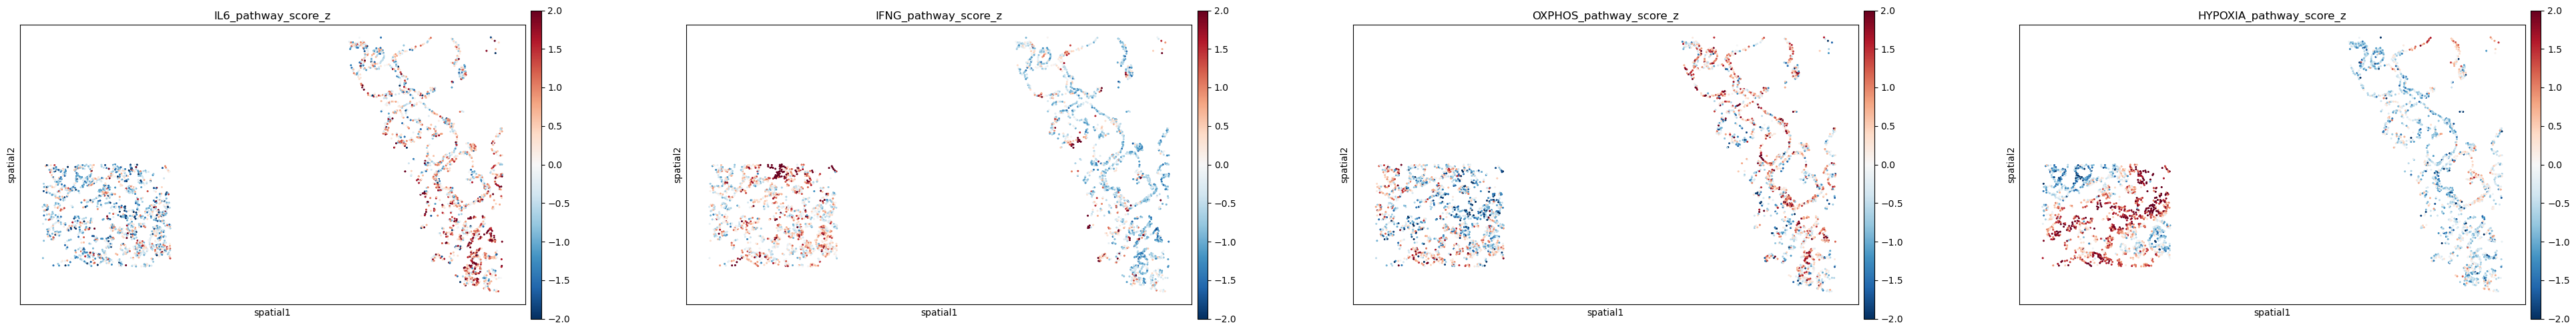

In [10]:
merged = subsets["MH065_480"]
for key in ['NOTCH_pathway_score', 'TGFB_pathway_score', 'IL6_pathway_score', 'SQUAMOUS_pathway_score', 'INFLAMMATORY_pathway_score', 'OXPHOS_pathway_score', 'IFNG_pathway_score', 'HYPOXIA_pathway_score', 'TREATMENT_pathway_score', 'TNF_pathway_score', 'TNF_NFKB_pathway_score', 'WNT_pathway_score', 'TIGIT_pathway_score', 'PD1_pathway_score']:
    vals = merged.obs[key]
    merged.obs[key + "_z"] = (vals - vals.mean()) / vals.std()

sq.pl.spatial_scatter(
    merged,
    library_id="spatial",
    shape=None,
    color=['IL6_pathway_score_z','IFNG_pathway_score_z', 'OXPHOS_pathway_score_z','HYPOXIA_pathway_score_z',
    ],
    wspace=0.2,
    size=4,
    cmap='RdBu_r',
     vmin=-2, vmax=2,
    save='MH065_signalling_scatter.pdf',
    figsize = (10,6)
)

## 4. Paired comparison across the three 480-gene samples

The mean score per sample and region, compared with a paired t-test. The original values are below for comparison.

HYPOXIA_pathway_score: paired t-test p = 0.0031 (original 0.0031)


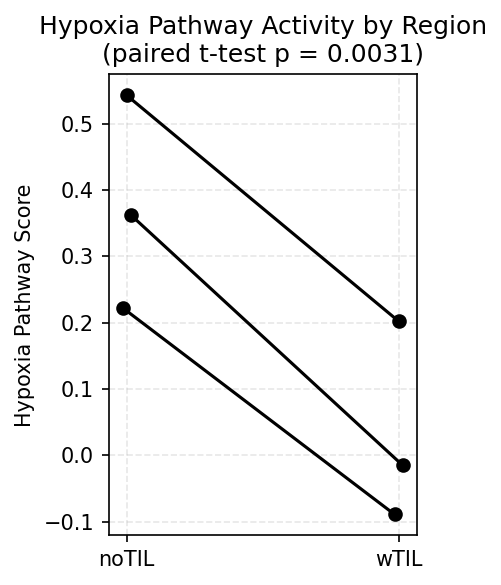

IL6_pathway_score: paired t-test p = 0.1545 (original 0.1545)


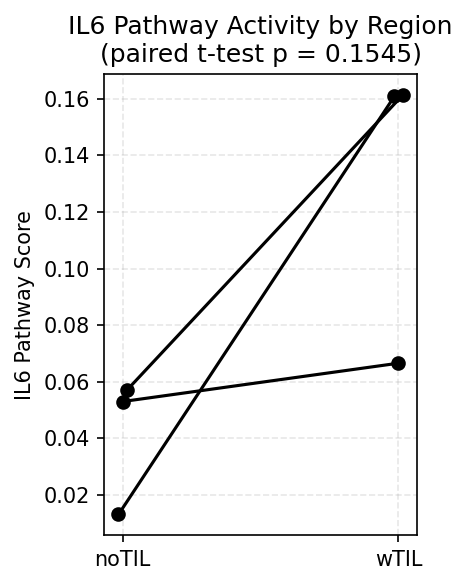

OXPHOS_pathway_score: paired t-test p = 0.1303 (original 0.1303)


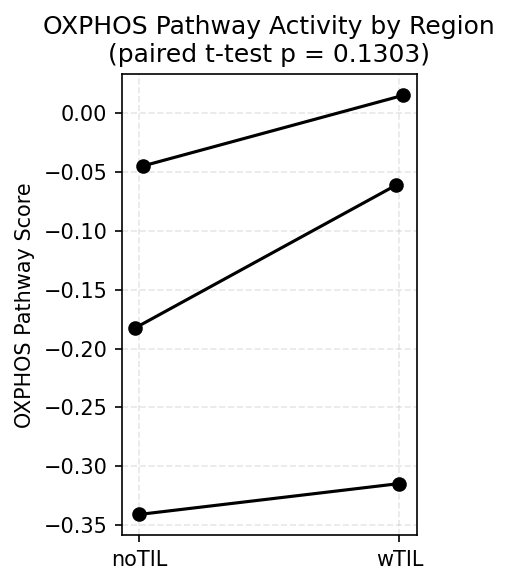

,sample_id,Region,HYPOXIA_pathway_score_difference,IL6_pathway_score_difference,OXPHOS_pathway_score_difference
0,MH065,noTIL,3.764618e-07,2.739812e-07,1.615962e-07
1,MH065,wTIL,3.335812e-08,3.320369e-07,4.637024e-07
2,MH106,noTIL,4.893443e-08,1.433241e-07,8.320903e-08
3,MH106,wTIL,4.779157e-07,2.750730e-07,4.930138e-07
4,MH107,noTIL,4.210167e-07,3.003287e-07,1.559819e-07
5,MH107,wTIL,4.571669e-07,4.411127e-07,2.440734e-07


In [11]:
combined_obs = pd.concat([subsets[s].obs.assign(sample_id=s.split("_")[0]) for s in PAIRED_SAMPLES])

# Original means per sample and region, from TILs_plotting_final.ipynb
original_means = pd.DataFrame({
    "sample_id": ["MH065", "MH065", "MH106", "MH106", "MH107", "MH107"],
    "Region": ["noTIL", "wTIL"] * 3,
    "HYPOXIA_pathway_score": [0.222496, -0.089222, 0.542935, 0.202069, 0.362537, -0.015293],
    "IL6_pathway_score": [0.013108, 0.160845, 0.053014, 0.066567, 0.056981, 0.161269],
    "OXPHOS_pathway_score": [-0.182429, -0.061305, -0.340960, -0.314693, -0.044739, 0.015326],
})
original_p = {"HYPOXIA_pathway_score": 0.0031, "IL6_pathway_score": 0.1545, "OXPHOS_pathway_score": 0.1303}


def paired_plot(score, label, name):
    grouped = combined_obs.groupby(['sample_id', 'Region'], observed=True)[score].mean().reset_index()
    pivot = grouped.pivot(index='sample_id', columns='Region', values=score)
    stat, pval = ttest_rel(pivot['wTIL'], pivot['noTIL'])
    print(f"{score}: paired t-test p = {pval:.4f} (original {original_p[score]:.4f})")

    plt.figure(figsize=(3, 4), dpi=150)
    x_vals = [0, 1]
    for i, (sample_id, row) in enumerate(pivot.iterrows()):
        jitter = (i - 1) * 0.015
        plt.plot([x + jitter for x in x_vals], [row['noTIL'], row['wTIL']], color='black', marker='o', label=sample_id)
    plt.xticks([0, 1], ['noTIL', 'wTIL'])
    plt.ylabel(f'{label} Pathway Score')
    plt.title(f'{label} Pathway Activity by Region\n(paired t-test p = {pval:.4f})')
    plt.grid(True, linestyle='--', alpha=0.3)
    plt.tight_layout()
    plt.savefig(os.path.join(FIGURE_DIR, name))
    plt.show()
    return grouped.assign(paired_t_test_p=pval)


results = [
    paired_plot("HYPOXIA_pathway_score", "Hypoxia", "Hypoxia_score_TIL.pdf"),
    paired_plot("IL6_pathway_score", "IL6", "IL6_score_TIL.pdf"),
    paired_plot("OXPHOS_pathway_score", "OXPHOS", "OXPHOS_score_TIL.pdf"),
]
means = results[0].merge(results[1], on=["sample_id", "Region"]).merge(results[2], on=["sample_id", "Region"])
means.to_csv(os.path.join(OUTPUT_DIR, "paired_pathway_scores.tsv"), sep="\t", index=False)

check = means.merge(original_means, on=["sample_id", "Region"], suffixes=("", "_original"))
for score in original_p:
    check[f"{score}_difference"] = (check[score] - check[f"{score}_original"]).abs()
display(check[["sample_id", "Region"] + [f"{s}_difference" for s in original_p]])

## 5. Check against the original subsets

Compares the cells in each region and the DE results with the original subset objects. In a passing run, the cells are the same and the DE differences are 0.

In [12]:
rows = []
for sample, file_name in archived_files.items():
    path = os.path.join(ARCHIVED_DIR, file_name) if ARCHIVED_DIR else None
    if not path or not os.path.exists(path):
        print(f"{sample}: no original subset object")
        continue
    reference = sc.read_h5ad(path)
    new = subsets[sample]
    shared = new.obs_names.intersection(reference.obs_names)
    row = {
        "sample": sample,
        "cells": new.n_obs,
        "cells_original": reference.n_obs,
        "shared": len(shared),
        "only_new": new.n_obs - len(shared),
        "only_original": reference.n_obs - len(shared),
        "same_region": f"{(new.obs.loc[shared, 'Region'].astype(str) == reference.obs.loc[shared, 'Region'].astype(str)).mean():.4%}",
    }
    if "rank_genes_groups" in reference.uns and reference.uns["rank_genes_groups"]["params"]["groupby"] == "Region":
        for group in ["wTIL", "noTIL"]:
            a = pd.DataFrame({k: new.uns["rank_genes_groups"][k][group] for k in ["names", "logfoldchanges", "pvals"]}).set_index("names")
            b = pd.DataFrame({k: reference.uns["rank_genes_groups"][k][group] for k in ["names", "logfoldchanges", "pvals"]}).set_index("names")
            genes = a.index.intersection(b.index)
            row[f"{group}_top10_same"] = list(a.index[:10]) == list(b.index[:10])
            row[f"{group}_logFC_max_difference"] = float((a.loc[genes, "logfoldchanges"] - b.loc[genes, "logfoldchanges"]).abs().max())
    rows.append(row)

check = pd.DataFrame(rows)
check.to_csv(os.path.join(OUTPUT_DIR, "stage3_malignant_check.tsv"), sep="\t", index=False)
display(check)

MH106_314: no original subset object


,sample,cells,cells_original,shared,only_new,only_original,same_region,wTIL_top10_same,wTIL_logFC_max_difference,noTIL_top10_same,noTIL_logFC_max_difference
0,MH065_480,3126,3126,3126,0,0,100.0000%,True,0.0,True,0.0
1,MH106_480,2271,2271,2271,0,0,100.0000%,True,0.0,True,0.0
2,MH107_480,1720,1720,1720,0,0,100.0000%,True,0.0,True,0.0
